<a href="https://colab.research.google.com/github/AriyaAzamatova/Kazakh_Latin_Signs_Almaty_2026/blob/main/Fig_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

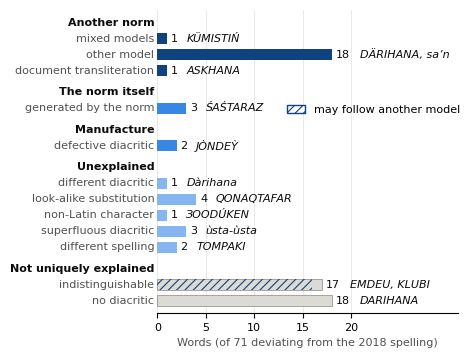

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# Рисунок 6: типы отклонений от написания 2018 г. (71 слово)
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Цвета
INK, INK2, GRID, EDGE = "#0b0b0b", "#52514e", "#e6e5e1", "#898781"
DARK, MID, LIGHT, GREY = "#104281", "#3987e5", "#86b6ef", "#dcdad4"

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8,
                     "savefig.dpi": 600, "hatch.linewidth": 0.8})
CM = 1 / 2.54

# Данные: группа, цвет, затем (категория, число слов, пример)
groups = [
    ("Another norm", DARK, [
        ("mixed models", 1, "KÜMISTIŃ"),
        ("other model", 18, "DÄRIHANA, sa’n"),
        ("document transliteration", 1, "ASKHANA")]),
    ("The norm itself", MID, [
        ("generated by the norm", 3, "ŚAŚTARAZ")]),
    ("Manufacture", MID, [
        ("defective diacritic", 2, "JÒNDEỲ")]),
    ("Unexplained", LIGHT, [
        ("different diacritic", 1, "Dàrihana"),
        ("look-alike substitution", 4, "QONAQTAFAR"),
        ("non-Latin character", 1, "ЗOODÚKEN"),
        ("superfluous diacritic", 3, "ùsta-ùsta"),
        ("different spelling", 2, "TOMPAKI")]),
    ("Not uniquely explained", GREY, [
        ("indistinguishable", 17, "EMDEU, KLUBI"),
        ("no diacritic", 18, "DARIHANA")]),
]
# Проверка: сумма должна быть 71
assert sum(n for _, _, cs in groups for _, n, _ in cs) == 71

fig, ax = plt.subplots(figsize=(12 * CM, 9.2 * CM))
y = 0
for g, col, cats in groups:
    ax.text(-0.3, y, g, ha="right", va="center", fontsize=8, fontweight="bold", color=INK)
    y += 1
    for name, n, ex in cats:
        ax.barh(y, n, height=0.7, color=col, edgecolor=EDGE if col == GREY else "none",
                linewidth=0.5 if col == GREY else 0)
        if name == "indistinguishable":      # штриховка на 16 словах из 17
            ax.barh(y, 16, height=0.7, color="none", edgecolor=DARK, hatch="////", linewidth=0)
        ax.text(n + 0.4, y, f"{n}", va="center", ha="left", fontsize=8, color=INK)
        ax.text(n + (2.0 if n < 10 else 2.9), y, ex, va="center", ha="left",
                fontsize=8, color=INK, style="italic")
        ax.text(-0.3, y, name, ha="right", va="center", fontsize=8, color=INK2)
        y += 1
    y += 0.35

ax.set_ylim(y - 0.6, -0.8)
ax.set_xlim(0, 31)
ax.set_yticks([])
ax.set_xticks([0, 5, 10, 15, 20])
ax.set_xlabel("Words (of 71 deviating from the 2018 spelling)", color=INK2, fontsize=8)
ax.grid(axis="x", color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)

# Легенда для штриховки
ax.add_patch(Rectangle((0, 0), 0, 0, facecolor="white", edgecolor=DARK, hatch="////",
                       label="may follow another model"))
ax.legend(loc="upper left", bbox_to_anchor=(0.40, 0.72), frameon=False,
          fontsize=8, handlelength=1.6)

fig.tight_layout()
fig.savefig("Fig_6_explanations.png")
fig.savefig("Fig_6_explanations.pdf")
plt.show()

# Скачивание файлов (работает только в Google Colab)
try:
    from google.colab import files
    files.download("Fig_6_explanations.png")
    files.download("Fig_6_explanations.pdf")
except ImportError:
    print("Файлы сохранены в папке, где запущен код")